In [1]:
from pathlib import Path
import os
import pickle as pkl

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch, Ellipse
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors
import matplotlib.patheffects as pe

import seaborn as sns

from scipy.stats import ttest_ind
import scipy.signal.signaltools  # keep only if you actually use it

from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

import anndata
import gseapy as gp
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.utils import load_example_data


## Data loading and preprocessing

In [2]:
adata = anndata.read_h5ad("INPUT/BulkRNAseq/Brb_seq_Gastruloid_drug.h5ad")

# Create deseq2 object

counts_df = pd.DataFrame(
    adata.X,
    index=adata.obs.index,
    columns=adata.var.index,
)

metadata = adata.obs.copy()

dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata,
    design_factors="group",
    refit_cooks=True,
    n_cpus=8,
)

dds.var_names_make_unique()
dds.deseq2()



Using None as control genes, passed at DeseqDataSet initialization


/Users/mleonard/opt/anaconda3/envs/rnaseq-pydeseq2/lib/python3.11/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/mleonard/opt/anaconda3/envs/rnaseq-pydeseq2/lib/python3.11/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_7536/3576534970.py:13: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 3.47 seconds.

Fitting dispersion trend curve...
... done in 0.37 seconds.

Fitting MAP dispersions...
... done in 6.49 seconds.

Fitting LFCs...
... done in 5.59 secon

## PCA on marker genes

In [3]:
# Load cell type marker genes

marker_genes = pd.read_csv('INPUT/marker_genes.csv')
marker_genes_dict =  {
    col: marker_genes[col].dropna().tolist()
    for col in marker_genes.columns
}
marker_genes_dict.pop('Unnamed_8', None)

unique_marker_genes = (
    pd.Series(
        gene
        for genes in marker_genes_dict.values()
        for gene in genes
    )
    .drop_duplicates()
    .tolist()
)

In [4]:
# data on cell type marker genes only
markers_set = set(unique_marker_genes)

sel_genes = [g for g in dds.var_names if g in markers_set]
print(f"{len(sel_genes)} marker genes found in dds out of {len(unique_marker_genes)} total markers.")
dds_filt = dds[dds.obs["group"].astype(str) != "72h"].copy()

dds_sel = dds_filt [:, sel_genes].copy()

357 marker genes found in dds out of 370 total markers.


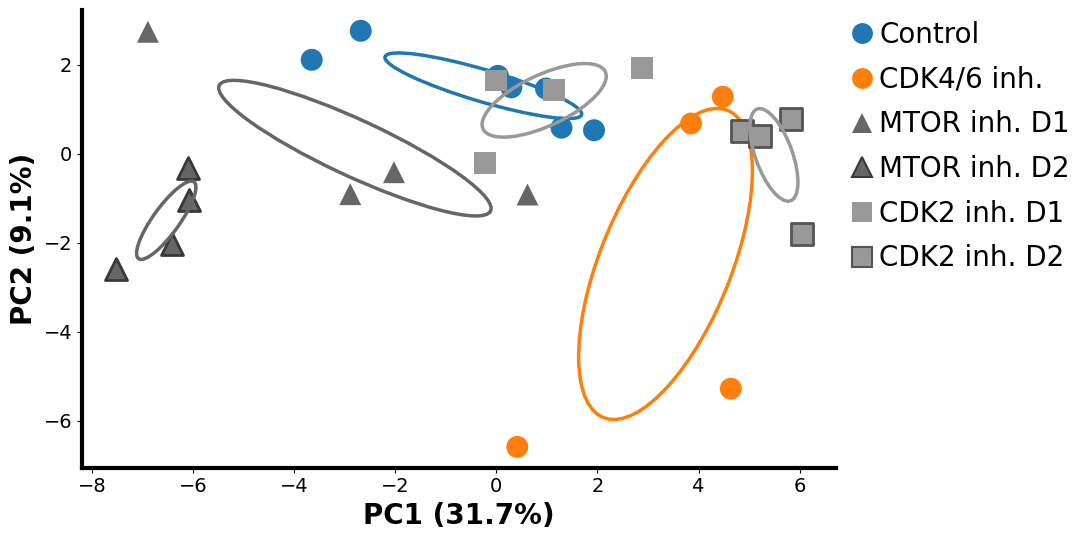

In [ ]:
# --- PCA of log-transformed normalised counts ---
X = np.log1p(dds_sel.layers["normed_counts"])
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)
expl = pca.explained_variance_ratio_



# --- Styling 
style_map = {
    "120h":  ("Control",       "tab:blue",   False, "o"),
    "cdk1":  ("CDK4/6 inh.",    "tab:orange", False, "o"),
    "mtor1": ("MTOR inh. D1",   "#666666",    False, "^"),
    "mtor2": ("MTOR inh. D2",   "#666666",    True,  "^"),
    "nu1":   ("CDK2 inh. D1",   "#999999",    False, "s"),
    "nu2":   ("CDK2 inh. D2",   "#999999",    True,  "s"),
}

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.set_facecolor("white")

for g in sorted(groups.unique()):
    mask = (groups == g).to_numpy()
    Xg = pcs[mask, :2]
    label, color, emphasise_edge, marker = style_map.get(g, (g, "tab:gray", False, "o"))
    edge = tuple(np.array(mcolors.to_rgb(color)) * 0.55) if emphasise_edge else "none"

    ax.scatter(
        Xg[:, 0], Xg[:, 1],
        s=250, c=color, marker=marker,
        edgecolors=edge, linewidths=2.0 if emphasise_edge else 0.0
    )

    # Ellipse from fitted covariance
    if Xg.shape[0] >= 2:
        gmm = GaussianMixture(n_components=1, covariance_type="full", random_state=0).fit(Xg)
        mean = gmm.means_[0]
        cov = gmm.covariances_[0]
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
        width, height = 2 * np.sqrt(vals)
        ax.add_patch(Ellipse(mean, width, height, angle=angle,
                             edgecolor=color, facecolor="none", lw=2.5))

# --- Axes formatting ---
ax.set_xlabel(f"PC1 ({expl[0]*100:.1f}%)", fontweight="bold", fontsize=20)
ax.set_ylabel(f"PC2 ({expl[1]*100:.1f}%)", fontweight="bold", fontsize=20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(3)
ax.spines["left"].set_linewidth(3)
ax.tick_params(axis="both", which="major", labelsize=14)

# --- Legend ---
present = set(groups.unique())
order = [k for k in style_map.keys() if k in present]
handles, labels = [], []
for k in order:
    lab, col, emphasise_edge, marker = style_map[k]
    edge = tuple(np.array(mcolors.to_rgb(col)) * 0.55) if emphasise_edge else "none"
    handles.append(Line2D([0], [0], linestyle="none", marker=marker,
                          markersize=15, markerfacecolor=col,
                          markeredgecolor=edge, markeredgewidth=1.5))
    labels.append(lab)

fig.subplots_adjust(right=0.77)
ax.legend(handles, labels, frameon=False, fontsize=20,
          handlelength=0, handletextpad=0.6, labelspacing=0.6,
          loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

plt.tight_layout()

# --- Save
outpath = "figures/PCA_marker_genes.pdf"
plt.savefig(outpath, format="pdf", dpi=500, transparent=True, bbox_inches="tight")

plt.show()

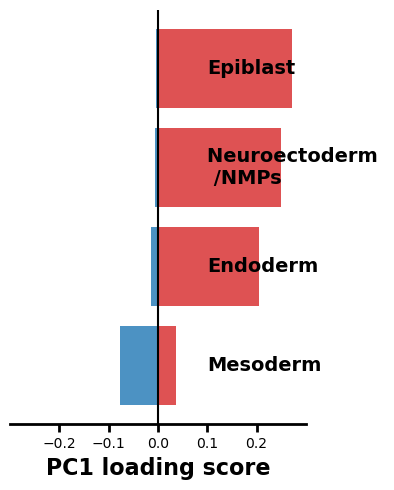

In [40]:



# ---- 1) Merge marker genes into broader categories ----
category_map = {
    "Naive pluripotency": "Naive pluripotency",
    "Epiblast": "Epiblast",
    "Primitive streak": "Primitive streak",
    "Cardiac Mesoderm": "Mesoderm",
    "Early mesoderm": "Early Mesoderm",
    "Somitic mesoderm": "Mesoderm",
    "Ectoderm": "Neuroectoderm \n /NMPs",
}

merged_markers = {}
for k, genes in marker_genes_dict.items():
    cat = category_map.get(k, k)
    merged_markers.setdefault(cat, []).extend(genes)

# ---- 2) Compute PC1 positive / negative loading scores ----
feat_upper = pd.Index(dds_sel.var_names).astype(str).str.upper()
pc1_vec = pca.components_[0]

upper_to_idx = (
    pd.Series(np.arange(len(feat_upper)), index=feat_upper)
      .groupby(level=0)
      .first()
)

rows = []
for cat, genes in merged_markers.items():
    genes_u = pd.Index(pd.Series(genes, dtype=str)).str.upper().unique()
    idx = upper_to_idx.reindex(genes_u).dropna().astype(int).to_numpy()
    if idx.size == 0:
        continue

    w = pc1_vec[idx]
    pos = float(np.sum(w[w > 0] ** 2))
    neg = float(np.sum(w[w < 0] ** 2))

    rows.append({
        "group": cat,
        "PC1_pos_score": pos,
        "PC1_neg_score": neg,
        "PC1_total": pos + neg,
    })

pc1_scores = pd.DataFrame(rows)

# ---- 3) Plot  ----
plot_df = (
    pc1_scores[
        ~pc1_scores["group"].isin(
            ["Naive pluripotency", "Early Mesoderm", "Primitive streak"]
        )
    ]
    .sort_values("PC1_total", ascending=True)
)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(4, 5))

neg_color = "#1f77b4"  # blue
pos_color = "#d62728"  # red

ax.barh(y, -plot_df["PC1_neg_score"], color=neg_color, alpha=0.8)
ax.barh(y,  plot_df["PC1_pos_score"], color=pos_color, alpha=0.8)
ax.axvline(0, color="black", linewidth=1.5)

max_extent = max(
    plot_df["PC1_pos_score"].max(),
    plot_df["PC1_neg_score"].max()
)
ax.set_xlim(-1.1 * max_extent, max(1.1 * max_extent, 0.2))

ax.set_yticks([])
for name, spine in ax.spines.items():
    if name == "bottom":
        spine.set_linewidth(2)
    else:
        spine.set_visible(False)

ax.tick_params(axis="x", width=2, length=6, labelsize=10)
ax.tick_params(axis="y", left=False)
ax.set_xlabel("PC1 loading score", fontweight="bold", fontsize=16)

for yi, label in zip(y, plot_df["group"]):
    ax.text(
        0.1, yi, label,
        va="center", ha="left",
        fontsize=14, fontweight="bold",
        clip_on=False
    )

plt.tight_layout()

outpath = "figures/Score_marker_genes.pdf"
plt.savefig(outpath, format="pdf", dpi=500, transparent=True, bbox_inches="tight")


plt.show()


## Cell type deconvolution

We applied cell type deconvolution using the example commands provided in the Scaden GitHub repository (https://github.com/KevinMenden/scaden/tree/master
). The model was trained on the scRNA-seq dataset generated in this study, using our cell-type annotations.

In [22]:
df = pd.read_csv('INPUT/BulkRNASeq/Scaden_deconvolution.csv')
df.set_index('Unnamed: 0', inplace=True)

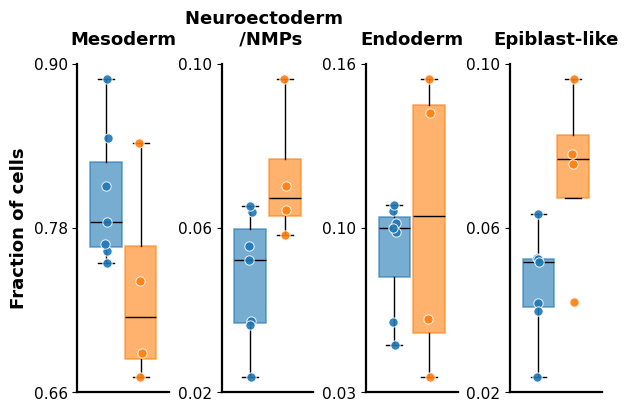

In [38]:
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

CATEGORIES = {
    "Mesoderm": [
        "Somite differentation front", "Late Cardiac mesoderm",
        "Early Cardiac mesoderm", "Endothelium", "Somite", "Early mesoderm"
    ],
    "Neuroectoderm \n /NMPs": ["Early NMPs", "Neuromesodermal progenitors"],
    "Endoderm": ["Early endoderm", "Endoderm"],
    "Epiblast-like": ["Primitive streak", "Epiblast", "Exiting pluripotency"],
}

COND_LABELS = ["Control", "CDK4/6 inhibitor"]
COND_COLORS = ["tab:blue", "tab:orange"]
BOX_ALPHA = 0.60
RNG = np.random.default_rng(42)

df_t = df.T  # cell-types x samples
samples_ctrl = [s for s in df_t.columns if "120h" in s]
samples_cdk  = [s for s in df_t.columns if "cdk1" in s]

def plot_category_panels(outpath,transform=None, ylabel="Fraction of cells"):
    fig, axes = plt.subplots(1, 4, figsize=(6, 4), constrained_layout=True, sharey=False)

    for k, (ax, (cat, members)) in enumerate(zip(axes, CATEGORIES.items())):
        members = [ct for ct in members if ct in df_t.index]

        ctrl = df_t.loc[members, samples_ctrl].sum(axis=0).to_numpy() if members and samples_ctrl else np.array([])
        cdk  = df_t.loc[members, samples_cdk ].sum(axis=0).to_numpy() if members and samples_cdk  else np.array([])

        vals = [ctrl, cdk]
        if transform is not None:
            vals = [transform(v) for v in vals]

        positions = [0.8, 1.4]
        bp = ax.boxplot(vals, positions=positions, widths=0.55, patch_artist=True, showfliers=False)

        for i, box in enumerate(bp["boxes"]):
            box.set_facecolor(COND_COLORS[i])
            box.set_edgecolor(COND_COLORS[i])
            box.set_alpha(BOX_ALPHA)
            box.set_linewidth(1.2)
        for key in ("whiskers", "caps", "medians"):
            for line in bp[key]:
                line.set_color("black")
                line.set_linewidth(1.0)

        for i, v in enumerate(vals):
            if v.size:
                jitter = (RNG.random(v.size) - 0.5) * 0.06
                ax.scatter(
                    np.full(v.size, positions[i]) + jitter, v,
                    s=45, color=COND_COLORS[i], alpha=0.9,
                    edgecolors="white", linewidths=0.7, zorder=3
                )

        ax.set_xticks([])
        ax.set_title(cat, fontsize=13, fontweight="bold", pad=14)
        if k == 0:
            ax.set_ylabel(ylabel, fontsize=13, fontweight="bold")

        ax.tick_params(axis="y", labelsize=11)
        # --- Y-axis formatting ---
        ymin, ymax = ax.get_ylim()
        yticks = [ymin, 0.5 * (ymin + ymax), ymax]

        ax.set_yticks(yticks)
        ax.set_yticklabels([f"{t:.2f}" for t in yticks])
        
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.6)
        ax.spines["bottom"].set_linewidth(1.6)

    # Optional legend:
    # handles = [Patch(facecolor=c, edgecolor=c, alpha=BOX_ALPHA, label=l)
    #            for c, l in zip(COND_COLORS, COND_LABELS)]
    # fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
    plt.savefig(outpath, format="pdf", dpi=500, transparent=True, bbox_inches="tight")
    
    plt.show()

outpath = 'figures/Brb_deconvolution_proportions.pdf'

plot_category_panels(outpath)


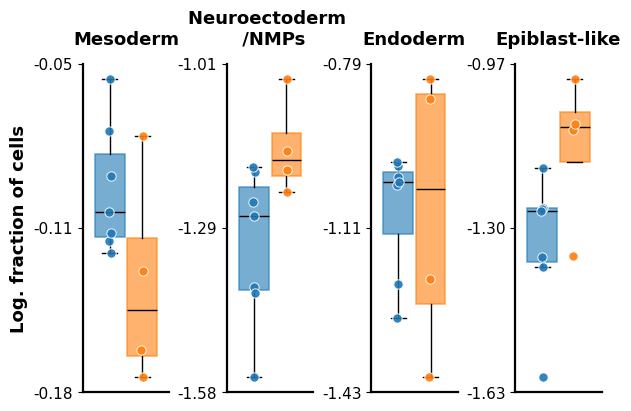

In [39]:
EPS = 1e-6
log10_safe = lambda x: np.log10(np.clip(x, EPS, None)) if x.size else x
outpath = 'figures/Brb_deconvolution_proportions_log.pdf'
plot_category_panels(outpath, transform=log10_safe, ylabel="Log. fraction of cells")


## Cell cycle signature of CDK4/6 inhibitor

In [3]:
def _overlap_to_int(x: str) -> int:
    """Parse Enrichr overlap 'k/M' and return k."""
    try:
        return int(str(x).split("/", 1)[0])
    except Exception:
        return np.nan


def run_enrichr_mouse(genes, libraries, cutoff: float = 0.5) -> pd.DataFrame:
    """Run Enrichr (Mouse) and return a tidy, sorted results table."""
    if not genes:
        return pd.DataFrame()

    enr = gp.enrichr(
        gene_list=[str(g) for g in genes],
        gene_sets=libraries,
        organism="Mouse",
        outdir=None,
        cutoff=cutoff,
    )
    res = getattr(enr, "results", None)
    if res is None or res.empty:
        return pd.DataFrame()

    res = res.rename(
        columns={
            "Term": "term",
            "Gene_set": "gene_set",
            "Adjusted P-value": "padj",
            "P-value": "pval",
            "Combined Score": "combined_score",
            "Overlap": "overlap",
            "Genes": "genes_in_term",
        }
    ).copy()

    res["gene_count"] = res["overlap"].map(_overlap_to_int)
    res["neglog10_padj"] = -np.log10(res["padj"].replace(0, np.nextafter(0, 1)))

    keep = [
        "gene_set",
        "term",
        "padj",
        "pval",
        "combined_score",
        "gene_count",
        "neglog10_padj",
        "overlap",
        "genes_in_term",
    ]
    return res[keep].sort_values(["padj", "combined_score"], ascending=[True, False])


def plot_go_dotplots(go_df: pd.DataFrame, direction: str, topn: int = 15) -> None:
    """Dotplot of top GO terms for a given direction."""
    if go_df.empty:
        print(f"No GO results for {direction}.")
        return

    gene_sets = ["GO_Biological_Process_2023"]
    titles = {"GO_Biological_Process_2023": "Biological Process"}

    fig, axes = plt.subplots(
        1, 3, figsize=(22, max(6, 0.55 * topn)), constrained_layout=True
    )
    axes = np.atleast_1d(axes)

    for ax, gs in zip(axes, gene_sets):
        sub = go_df.loc[go_df["gene_set"] == gs].copy()
        if sub.empty:
            ax.axis("off")
            ax.set_title(f"{titles[gs]} (no hits)")
            continue

        sub = (
            sub.sort_values(["padj", "combined_score"])
            .head(topn)
            .iloc[::-1]
        )

        sns.scatterplot(
            data=sub,
            x="neglog10_padj",
            y="term",
            size="gene_count",
            hue="combined_score",
            sizes=(40, 350),
            ax=ax,
            legend=False,
        )

        for _, r in sub.iterrows():
            ax.text(
                r["neglog10_padj"] * 1.01,
                r["term"],
                f"  n={int(r['gene_count'])}",
                va="center",
            )

        ax.set(
            xlabel=r"$-\log_{10}(\mathrm{adj}\;p)$",
            ylabel="",
            title=f"{titles[gs]} — {direction}",
        )
        ax.grid(True, axis="x")

    plt.suptitle(
        f"GO Enrichment (Mouse) — {direction.upper()}-regulated",
        y=1.02,
        fontsize=18,
    )
    plt.show()


In [4]:
cond = ['cdk1']

for con in cond: 
    stat_res= DeseqStats(dds, contrast=["group", con, "120h"], n_cpus=8)
    stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: group cdk1 vs 120h
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene_name                                                                   
Gnai3            153.075809        0.077855  0.098021  0.794271  0.427038   
Cdc45             48.445594       -0.000591  0.163932 -0.003603  0.997125   
H19              425.573376       -0.019673  0.089502 -0.219800  0.826027   
Scml2              2.959383        0.570519  0.606263  0.941042  0.346683   
Narf              39.071958       -0.141363  0.172689 -0.818600  0.413015   
...                     ...             ...       ...       ...       ...   
4933434E20Rik-3    0.498622       -0.883465  1.738161 -0.508276  0.611260   
Shld3              3.218878       -1.162742  0.707317 -1.643877  0.100202   
A930007A09Rik      0.681529       -0.688475  1.581500 -0.435330  0.663323   
CT010467.2         2.564100        0.890854  0.794579  1.121165  0.262217   
AC159819.1        7

... done in 1.46 seconds.



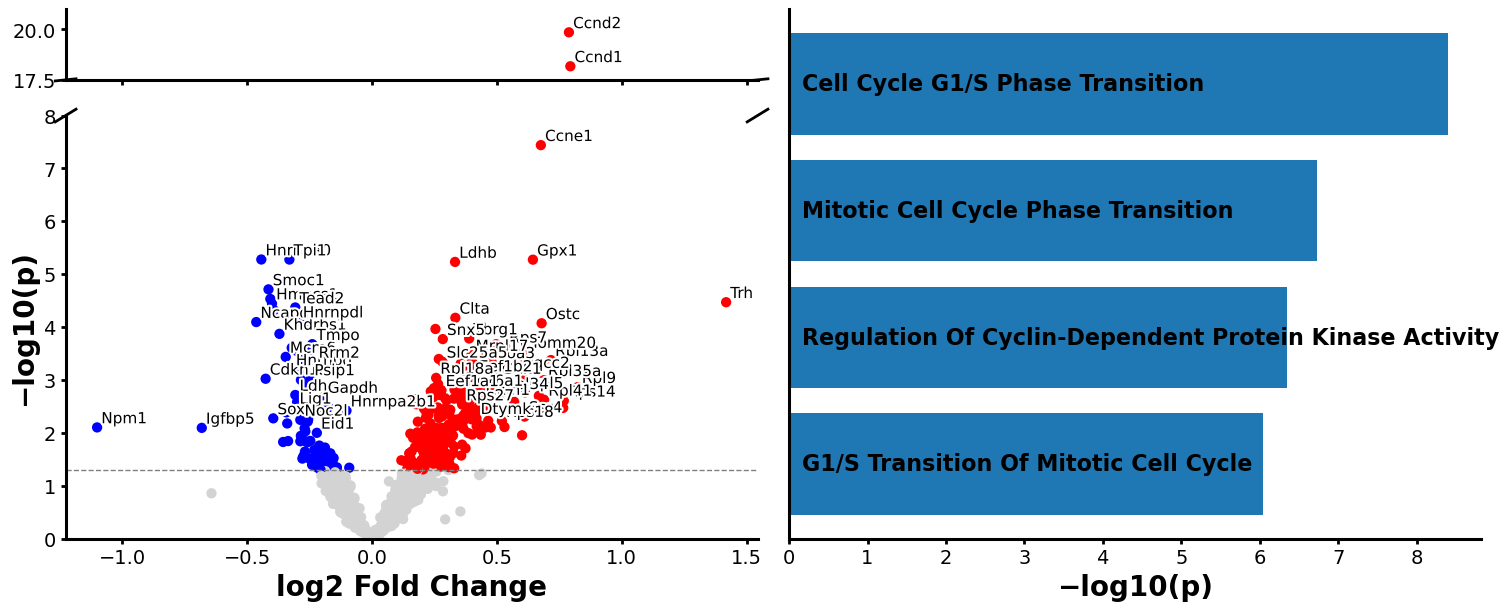

In [5]:
# Volcano (colour by p < 0.05) + GO BP bar plot (combined up+down; top 4)

ALPHA_ENR = 0.01     # enrichment selection on padj
ALPHA_COLOR = 0.05   # volcano colouring + reference line
LFC_THR = 0

df = (
    stat_res.results_df.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["log2FoldChange", "padj"])
    .copy()
)

pcol = "pvalue" if "pvalue" in df.columns else "padj"
df["neglog10_p"] = -np.log10(df[pcol].clip(lower=1e-300))

sig = df[pcol] < ALPHA_COLOR
pos = sig & (df["log2FoldChange"] > LFC_THR)
neg = sig & (df["log2FoldChange"] < -LFC_THR)
colors = np.where(pos, "red", np.where(neg, "blue", "lightgray"))

# Label candidates: p < 0.01, ranked by |LFC| * -log10(p)
sel = df[df["neglog10_p"] > 2].copy()
sel["rank_score"] = sel["log2FoldChange"].abs() * sel["neglog10_p"]
lab = pd.concat(
    [
        sel[sel["log2FoldChange"] > 0].nlargest(100, "rank_score"),
        sel[sel["log2FoldChange"] < 0].nlargest(100, "rank_score"),
    ]
).sort_values("rank_score", ascending=False)

# Enrichment input: padj < 0.01 (combined up+down)
sig_enr = df["padj"] < ALPHA_ENR
up_genes = df.index[sig_enr & (df["log2FoldChange"] > LFC_THR)].tolist()
dn_genes = df.index[sig_enr & (df["log2FoldChange"] < -LFC_THR)].tolist()
both_res = run_enrichr_mouse(up_genes + dn_genes, libraries=["GO_Biological_Process_2023"], cutoff=0.1)

bp = both_res[both_res["gene_set"] == "GO_Biological_Process_2023"].copy()
if not bp.empty:
    bp["term_clean"] = bp["term"].str.replace(r"\s*\(GO:\d+\)$", "", regex=True)
    bp["neglog10_p"] = -np.log10(bp["pval"].clip(lower=1e-300))
    bp = (
        bp.sort_values(["pval", "term_clean"], ascending=[True, True])
        .head(4)
        .iloc[::-1]
        .reset_index(drop=True)
    )


def draw_volcano(ax):
    ax.scatter(df["log2FoldChange"], df["neglog10_p"], s=55, c=colors, edgecolor="none")
    ax.axhline(-np.log10(ALPHA_COLOR), color="gray", linestyle="--", linewidth=1)

    for spine in ("left", "bottom"):
        ax.spines[spine].set_linewidth(2.2)
        ax.spines[spine].set_color("black")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="both", width=2)
    ax.grid(False)


def annotate_many(ax, labels_df, max_labels=999, px_dx=14, px_dy=10, fs=11):
    """Annotate many genes, skipping labels that overlap in pixel space."""
    trans = ax.transData
    placed, count = [], 0
    ymin, ymax = ax.get_ylim()

    for gene, r in labels_df.iterrows():
        x, y = r["log2FoldChange"], r["neglog10_p"]
        if not (ymin <= y <= ymax):
            continue

        xd, yd = trans.transform((x, y))
        if any(abs(xd - xp) < px_dx and abs(yd - yp) < px_dy for xp, yp in placed):
            continue

        ax.annotate(
            str(gene),
            (x, y),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=fs,
            color="black",
            clip_on=True,
            path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        )
        placed.append((xd, yd))
        count += 1
        if count >= max_labels:
            break


fig = plt.figure(figsize=(15, 6), constrained_layout=True)
gs = GridSpec(2, 2, width_ratios=[1, 1], height_ratios=[1, 6], figure=fig)

ax_top = fig.add_subplot(gs[0, 0])
ax_bot = fig.add_subplot(gs[1, 0], sharex=ax_top)
ax_right = fig.add_subplot(gs[:, 1])

draw_volcano(ax_bot)
draw_volcano(ax_top)

ax_bot.set_ylim(0, 8)
ax_top.set_ylim(17.5, 21)

ax_bot.set_xlabel("log2 Fold Change", fontsize=20, fontweight="bold")
ax_bot.set_ylabel("−log10(p)" if pcol == "pvalue" else "−log10(adj p)", fontsize=20, fontweight="bold")

for a in (ax_bot, ax_top):
    a.tick_params(axis="both", labelsize=14, width=2)
plt.setp(ax_top.get_xticklabels(), visible=False)

annotate_many(ax_bot, lab[lab["neglog10_p"].between(0, 8)], max_labels=200, fs=11, px_dx=14, px_dy=10)
annotate_many(ax_top, lab[lab["neglog10_p"].between(17.5, 21)], max_labels=120, fs=11, px_dx=14, px_dy=10)

# Axis break markers
d = 0.015
kw_t = dict(transform=ax_top.transAxes, color="black", clip_on=False, linewidth=2)
ax_top.plot((-d, +d), (-d, +d), **kw_t)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kw_t)
kw_b = dict(transform=ax_bot.transAxes, color="black", clip_on=False, linewidth=2)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kw_b)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kw_b)

# GO BP bar plot
ax = ax_right
ax.grid(False)

if bp.empty:
    ax.text(0.5, 0.5, "No GO BP terms", ha="center", va="center", fontsize=14, fontweight="bold")
    ax.axis("off")
else:
    bars = ax.barh(bp["term_clean"], bp["neglog10_p"])
    ax.set_xlabel("−log10(p)", fontsize=20, fontweight="bold")
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=14, width=2)
    ax.set_yticks([])

    xmax = float(bp["neglog10_p"].max())
    xstart = 0.02 * xmax
    for rect, term in zip(bars, bp["term_clean"]):
        y = rect.get_y() + rect.get_height() / 2
        ax.text(xstart, y, term, va="center", ha="left", fontsize=16, fontweight="bold", color="k")

    for spine in ("left", "bottom"):
        ax.spines[spine].set_linewidth(2.2)
        ax.spines[spine].set_color("black")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

plt.savefig("figures/volcano_go_bp.png", dpi=400, transparent=True, bbox_inches="tight")
plt.show()


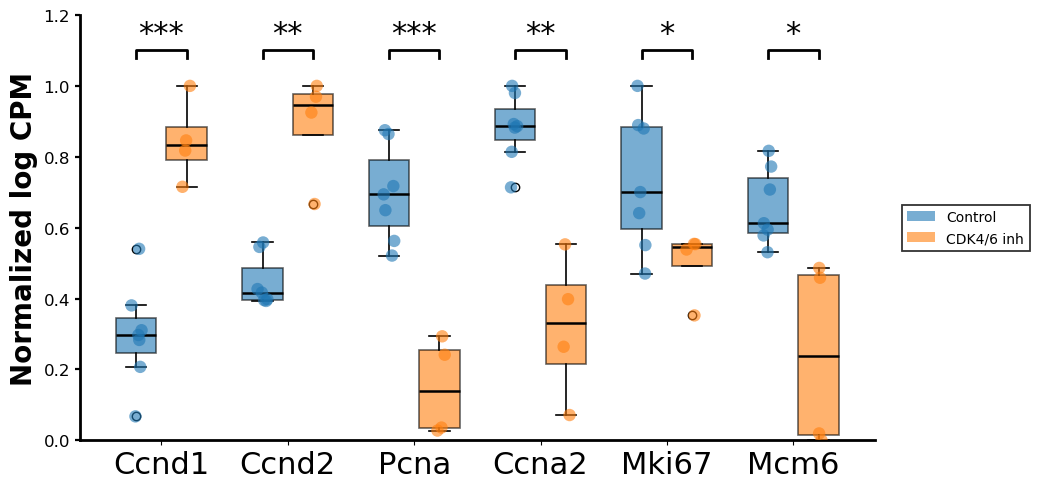

In [6]:


# ---------- CONFIG ----------
genes = ["Ccnd1", "Ccnd2", "Pcna", "Ccna2", "Mki67", "Mcm6"]
label_col = "group"
cond_labels = ["120h", "cdk1"]  # control, then CDK4/6 inhibition
color_map = {"120h": "tab:blue", "cdk1": "tab:orange"}
legend_map = {"120h": "Control", "cdk1": "CDK4/6 inh"}

alpha_fill = 0.6
box_width = 0.32
offset = 0.20

DOT_SIZE = 80
DOT_ALPHA = 0.6
JITTER = 0.045

XTICK_FONTSIZE = 22
SIG_FONTSIZE = 22
SIG_LINEWIDTH = 2.0

# ---------- NORMALISATION: CPM -> log1p ----------
X = dds.X.toarray() if hasattr(dds.X, "toarray") else np.asarray(dds.X)
lib_sizes = np.where(X.sum(axis=1) == 0, np.nan, X.sum(axis=1))
labels = dds.obs[label_col].astype(str).values

def log_cpm_for_gene(g):
    gi = dds.var_names.get_loc(g)
    return np.log1p((X[:, gi] / lib_sizes) * 1e6)

def scaled_0_1(arr):
    mn, mx = np.nanmin(arr), np.nanmax(arr)
    if not np.isfinite(mn) or not np.isfinite(mx) or mx == mn:
        return np.zeros_like(arr, dtype=float)
    return (arr - mn) / (mx - mn)

values_by_cond = {c: [] for c in cond_labels}
for g in genes:
    v = scaled_0_1(log_cpm_for_gene(g))
    for c in cond_labels:
        values_by_cond[c].append(v[labels == c])

# ---------- PLOT SETUP ----------
plt.rcParams.update({
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(10.5, 5))

x = np.arange(len(genes), dtype=float)
pos_A, pos_B = x - offset, x + offset

def draw_boxes(data, positions, color):
    bp = ax.boxplot(
        data, positions=positions, widths=box_width, patch_artist=True,
        manage_ticks=False, whis=1.5, showcaps=True, zorder=2,
        medianprops=dict(linewidth=1.8),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2),
    )
    for b in bp["boxes"]:
        b.set_facecolor(color)
        b.set_alpha(alpha_fill)
    for m in bp["medians"]:
        m.set_color("black")
    return bp

draw_boxes(values_by_cond[cond_labels[0]], pos_A, color_map[cond_labels[0]])
draw_boxes(values_by_cond[cond_labels[1]], pos_B, color_map[cond_labels[1]])

# ---------- SAMPLE DOTS ----------
rng = np.random.default_rng(42)
for i in range(len(genes)):
    for pos, cond in zip([pos_A, pos_B], cond_labels):
        vals = np.asarray(values_by_cond[cond][i], dtype=float)
        vals = vals[np.isfinite(vals)]
        if vals.size:
            xj = pos[i] + rng.uniform(-JITTER, JITTER, size=vals.size)
            ax.scatter(
                xj, vals, s=DOT_SIZE, alpha=DOT_ALPHA,
                color=color_map[cond], edgecolors="none", zorder=3
            )

ax.set_xticks(x)
ax.set_xticklabels(genes, fontsize=XTICK_FONTSIZE)
ax.set_ylabel("Normalized log CPM", fontsize=20, fontweight="bold")

for side in ["left", "bottom"]:
    ax.spines[side].set_linewidth(2.0)
    ax.spines[side].set_color("black")

ax.tick_params(axis="y", width=1.6, labelsize=12)

# ---------- LEGEND ----------
handles = [
    Patch(facecolor=color_map[c], alpha=alpha_fill, label=legend_map[c])
    for c in cond_labels
]
leg = ax.legend(
    handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
    frameon=True, fancybox=False, borderaxespad=0.8
)
leg.get_frame().set_edgecolor("black")
leg.get_frame().set_linewidth(1.3)

# ---------- SIGNIFICANCE (Welch t-test) ----------
def p_to_stars(p):
    if p < 1e-3: return "***"
    if p < 1e-2: return "**"
    if p < 0.05: return "*"
    return ""

ax.set_ylim(0, 1.20)
y_sig, h = 1.08, 0.02

for i in range(len(genes)):
    a = np.asarray(values_by_cond[cond_labels[0]][i], dtype=float)
    b = np.asarray(values_by_cond[cond_labels[1]][i], dtype=float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if not (a.size and b.size):
        continue

    _, p = ttest_ind(a, b, equal_var=False)
    stars = p_to_stars(p)
    if not stars:
        continue

    x1, x2 = pos_A[i], pos_B[i]
    ax.plot([x1, x1, x2, x2], [y_sig, y_sig + h, y_sig + h, y_sig],
            lw=SIG_LINEWIDTH, c="black", zorder=4)
    ax.text((x1 + x2) / 2, y_sig + h + 0.006, stars,
            ha="center", va="bottom", fontsize=SIG_FONTSIZE, zorder=4)

fig.tight_layout()
plt.savefig("figures/CC_genes_CPM.png", dpi=400, transparent=True, bbox_inches="tight")
plt.show()
